<a href="https://colab.research.google.com/github/mohanbaburlap-ctrl/part1/blob/main/part3visual.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pandas numpy matplotlib seaborn plotly -q

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

import os
import glob
import json
import warnings

warnings.filterwarnings("ignore")

plt.style.use("ggplot")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
from google.colab import files

uploaded = files.upload()

Saving categories.csv to categories.csv
Saving GBvideos.csv to GBvideos.csv
Saving INvideos.csv to INvideos.csv
Saving USvideos.csv to USvideos.csv


In [4]:
import shutil

os.makedirs("part3_visualization_eda/data", exist_ok=True)

for filename in uploaded.keys():
    shutil.move(
        filename,
        "part3_visualization_eda/data/" + filename
    )

print("Files uploaded successfully!")

Files uploaded successfully!


In [5]:
DATA_PATH = "part3_visualization_eda/data"

csv_files = glob.glob(DATA_PATH + "/*videos.csv")

country_data = []

for file in csv_files:

    df = pd.read_csv(file)

    country = os.path.basename(file).replace("videos.csv", "")

    df["country"] = country

    country_data.append(df)

youtube = pd.concat(country_data, ignore_index=True)

print("Combined dataset loaded!")
print("Shape:", youtube.shape)

youtube.head()

Combined dataset loaded!
Shape: (46230, 17)


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,country
0,u_nKn025TZS,17.14.11,Wild Winter Prank,OfficialRecipe78,28,2017-10-18T07:42:02.000Z,[none],84344,2155.0,163,475.0,https://i.ytimg.com/vi/u_nKn025TZS/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,GB
1,FoQAEGxMMQD,17.14.11,Wild Cricket Tutorial FINALE,FinalTrailer97,26,2017-11-14T12:56:18.000Z,Minecraft|Paris,230434,5412.0,330,1704.0,https://i.ytimg.com/vi/FoQAEGxMMQD/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,GB
2,wHqDBuStXq3,17.14.11,Epic Space Challenge,UltimateReview54,23,2017-11-13T06:19:10.000Z,Paris,338852,16813.0,1333,1385.0,https://i.ytimg.com/vi/wHqDBuStXq3/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,GB
3,ZId0IGzSaaZ,17.14.11,Quiet Paris Prank LIVE?!,FinalUpdate79,24,2017-11-14T11:37:33.000Z,Phones,160896,4221.0,483,1342.0,https://i.ytimg.com/vi/ZId0IGzSaaZ/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,GB
4,1-xA4eRrYSH,17.14.11,Nova Kane - Chess (Official Video)!,QuietInterview9,10,2017-11-14T03:13:26.000Z,Chess|Minecraft|Festival|Guitar,59441,1475.0,77,60.0,https://i.ytimg.com/vi/1-xA4eRrYSH/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,GB


In [6]:
categories = pd.read_csv(DATA_PATH + "/categories.csv")

print(categories.head())
print(categories.columns)

   category_id     category_name
0            1  Film & Animation
1            2  Autos & Vehicles
2           10             Music
3           15    Pets & Animals
4           17            Sports
Index(['category_id', 'category_name'], dtype='object')


In [7]:
print("Dataset Shape:")
print(youtube.shape)

print("\nColumn Names:")
print(youtube.columns.tolist())

print("\nData Types:")
print(youtube.dtypes)

print("\nDataset Information:")
youtube.info()

Dataset Shape:
(46230, 17)

Column Names:
['video_id', 'trending_date', 'title', 'channel_title', 'category_id', 'publish_time', 'tags', 'views', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'video_error_or_removed', 'description', 'country']

Data Types:
video_id                   object
trending_date              object
title                      object
channel_title              object
category_id                 int64
publish_time               object
tags                       object
views                       int64
likes                     float64
dislikes                    int64
comment_count             float64
thumbnail_link             object
comments_disabled            bool
ratings_disabled             bool
video_error_or_removed       bool
description                object
country                    object
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46230 entries, 0 to 46229
Da

In [8]:
missing = youtube.isnull().sum()

missing_percentage = (
    youtube.isnull().mean() * 100
)

missing_report = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": missing_percentage
})

missing_report = missing_report[
    missing_report["Missing Count"] > 0
]

print(missing_report)

               Missing Count  Missing Percentage
likes                     12            0.025957
comment_count             36            0.077872
description             1624            3.512870


In [9]:
print("Before cleaning:", youtube.shape)

# Remove duplicate records
youtube = youtube.drop_duplicates()

# Remove records marked as removed videos
if "video_error_or_removed" in youtube.columns:

    youtube = youtube[
        youtube["video_error_or_removed"] == False
    ]

# Convert numeric columns
numeric_columns = [
    "views",
    "likes",
    "dislikes",
    "comment_count"
]

for col in numeric_columns:
    if col in youtube.columns:
        youtube[col] = pd.to_numeric(
            youtube[col], errors="coerce"
        )

# Convert trending date
# Kaggle YouTube dataset commonly uses YY.DD.MM
youtube["trending_date"] = pd.to_datetime(
    youtube["trending_date"],
    format="%y.%d.%m",
    errors="coerce"
)

# Convert publish time
youtube["publish_time"] = pd.to_datetime(
    youtube["publish_time"],
    errors="coerce",
    utc=True
)

print("After cleaning:", youtube.shape)

Before cleaning: (46230, 17)
After cleaning: (45908, 17)


In [10]:
youtube["days_to_trend"] = (
    youtube["trending_date"].dt.normalize()
    -
    youtube["publish_time"].dt.tz_localize(None).dt.normalize()
).dt.days

youtube = youtube[
    youtube["days_to_trend"].notna()
    & (youtube["days_to_trend"] >= 0)
]

print(youtube[
    ["video_id", "days_to_trend"]
].head())

      video_id  days_to_trend
0  u_nKn025TZS             27
1  FoQAEGxMMQD              0
2  wHqDBuStXq3              1
3  ZId0IGzSaaZ              0
4  1-xA4eRrYSH              0


In [11]:
print("Final Dataset Shape:", youtube.shape)

print("\nData Types:")
print(youtube.dtypes)

print("\nMissing Values:")
print(
    youtube.isnull().mean()
    .mul(100)
    .loc[lambda x: x > 0]
)

print("\nCleaning completed!")

Final Dataset Shape: (45908, 18)

Data Types:
video_id                               object
trending_date                  datetime64[ns]
title                                  object
channel_title                          object
category_id                             int64
publish_time              datetime64[ns, UTC]
tags                                   object
views                                   int64
likes                                 float64
dislikes                                int64
comment_count                         float64
thumbnail_link                         object
comments_disabled                        bool
ratings_disabled                         bool
video_error_or_removed                   bool
description                            object
country                                object
days_to_trend                           int64
dtype: object

Missing Values:
likes            0.026139
comment_count    0.078418
description      3.511371
dtype: float64

C

In [15]:
import os

os.makedirs(
    "part3_visualization_eda/charts",
    exist_ok=True
)

print("Charts folder created successfully!")

Charts folder created successfully!


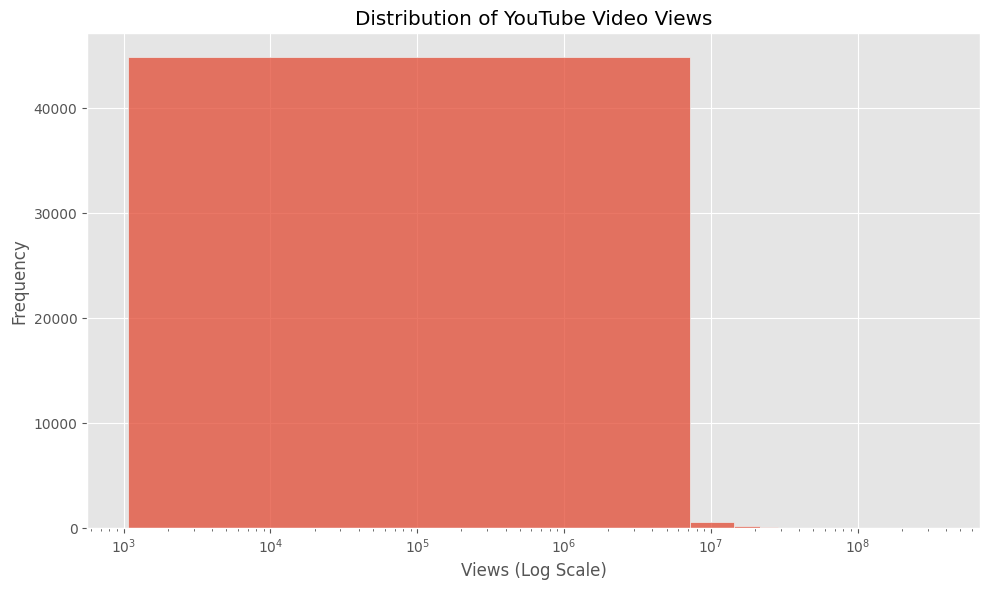

In [16]:
plt.figure(figsize=(10, 6))

sns.histplot(daily_trending = (
    youtube.groupby("trending_date")["video_id"]
    .count()
)

plt.figure(figsize=(14, 6))

plt.plot(
    daily_trending.index,
    daily_trending.values,
    marker="o"
)

plt.title("YouTube Trending Records Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Trending Records")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "part3_visualization_eda/charts/trending_over_time.png"
)

plt.show()
    data=youtube,
    x="views",
    bins=50
)

plt.xscale("log")

plt.title("Distribution of YouTube Video Views")
plt.xlabel("Views (Log Scale)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig(
    "part3_visualization_eda/charts/views_histogram.png"
)
plt.show()

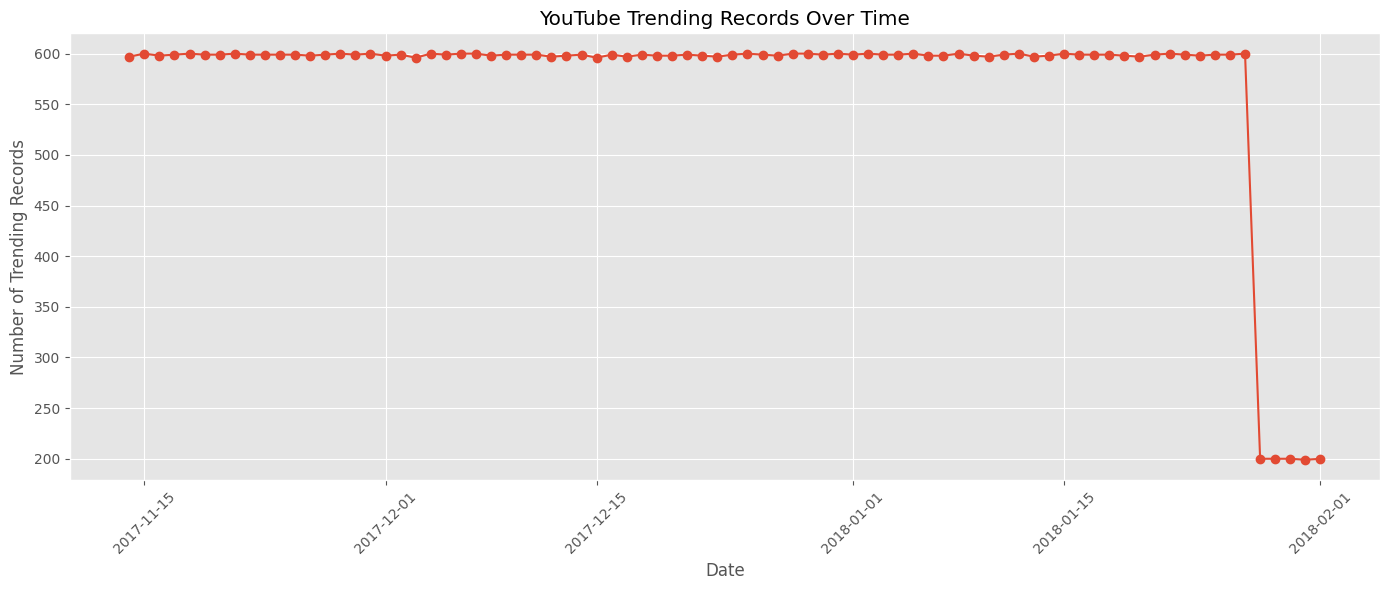

In [17]:

daily_trending = (
    youtube.groupby("trending_date")["video_id"]
    .count()
)

plt.figure(figsize=(14, 6))

plt.plot(
    daily_trending.index,
    daily_trending.values,
    marker="o"
)

plt.title("YouTube Trending Records Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Trending Records")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "part3_visualization_eda/charts/trending_over_time.png"
)

plt.show()

In [21]:
sample_data = youtube.sample(
    min(5000, len(youtube)),
    random_state=42
)

fig = px.scatter(
    sample_data,
    x="views",
    y="likes",  # or whichever y-axis column you are using
    color="category_id"  # Changed from category_name to category_id
)

fig.update_layout(
    xaxis_title="Views (Log Scale)",
    yaxis_title="Likes (Log Scale)"
)

fig.show()

fig.write_html(
    "part3_visualization_eda/charts/views_likes_interactive.html"
)

In [23]:
# 1. Define the columns you want to analyze
columns = ['views', 'likes', 'comment_count']  # Replace with your actual column names

# 2. Run your loop
for col in columns:
    mean = youtube[col].mean()
    median = youtube[col].median()
    mode = youtube[col].mode().iloc[0]

    print(f"Column: {col} -> Mean: {mean}, Median: {median}, Mode: {mode}")


Column: views -> Mean: 1180231.9575455259, Median: 318570.0, Mode: 16000
Column: likes -> Mean: 45873.442631166115, Median: 10213.0, Mode: 0.0
Column: comment_count -> Mean: 3454.188982385769, Median: 1074.0, Mode: 0.0


In [24]:
for col in ["views", "likes"]:

    Q1 = youtube[col].quantile(0.25)

    Q3 = youtube[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR

    upper = Q3 + 1.5 * IQR

    outliers = youtube[
        (youtube[col] < lower) |
        (youtube[col] > upper)
    ]

    print("\nColumn:", col)

    print("Q1:", Q1)

    print("Q3:", Q3)

    print("IQR:", IQR)

    print("Lower Limit:", lower)

    print("Upper Limit:", upper)

    print("Outlier Count:", len(outliers))


Column: views
Q1: 129578.5
Q3: 823935.75
IQR: 694357.25
Lower Limit: -911957.375
Upper Limit: 1865471.625
Outlier Count: 5073

Column: likes
Q1: 3656.0
Q3: 28989.25
IQR: 25333.25
Lower Limit: -34343.875
Upper Limit: 66989.125
Outlier Count: 5255


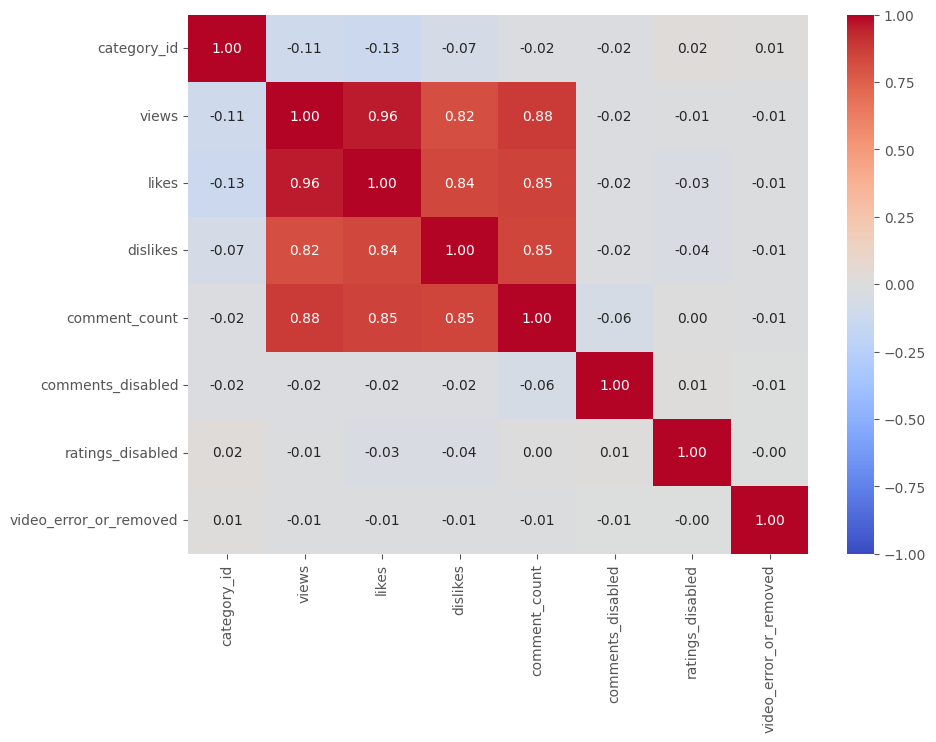

In [27]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Calculate the correlation matrix (use numeric_only=True to skip non-numeric columns)
correlation = df.corr(numeric_only=True)

# 2. Run your heatmap code
plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f",
)
plt.show()


In [28]:
corr_pairs = correlation.abs().unstack()

# Remove self-correlations
corr_pairs = corr_pairs[
    corr_pairs.index.get_level_values(0)
    !=
    corr_pairs.index.get_level_values(1)
]

# Keep each pair only once
corr_pairs.index = [
    tuple(sorted(pair))
    for pair in corr_pairs.index
]

corr_pairs = corr_pairs[
    ~corr_pairs.index.duplicated()
]

top_two = corr_pairs.sort_values(
    ascending=False
).head(2)

print("Two Strongest Correlations:")
print(top_two)

Two Strongest Correlations:
(likes, views)            0.960398
(comment_count, views)    0.882773
dtype: float64


In [36]:
video_days = (
    youtube[["video_id", "trending_date"]]
    .drop_duplicates()
    .sort_values("trending_date")
)

video_days["trending_day"] = (
    video_days.groupby("video_id")
    .cumcount() + 1
)

lifespan = (
    video_days.groupby("video_id")
    ["trending_day"]
    .max()
    .reset_index(name="lifespan")
)

print(lifespan.head())

      video_id  lifespan
0  --UQXlrk5E0         3
1  --j83Wp5WrQ         2
2  --pb5oKkYrH         4
3  -0B4eg2Srpi         3
4  -0dHuLKRPYS         6


In [37]:
total_unique = lifespan["video_id"].nunique()

retention_days = [1, 2, 3, 5, 7]

retention_results = []

for day in retention_days:

    remaining = (
        lifespan["lifespan"] >= day
    ).sum()

    percentage = (
        remaining / total_unique * 100
    )

    retention_results.append({
        "Day": day,
        "Videos Remaining": remaining,
        "Retention Percentage": round(
            percentage, 2
        )
    })

retention_df = pd.DataFrame(
    retention_results
)

print(retention_df)


   Day  Videos Remaining  Retention Percentage
0    1             14688                100.00
1    2              9335                 63.56
2    3              6250                 42.55
3    5              2951                 20.09
4    7              1510                 10.28


In [41]:
first_trending = (
    youtube.sort_values("trending_date")
    .drop_duplicates("video_id")
    [["video_id", "trending_date"]]
)

first_trending = first_trending.merge(
    lifespan,
    on="video_id",
    how="left"
)

first_trending["cohort_week"] = (
    first_trending["trending_date"]
    .dt.to_period("W")
    .astype(str)
)

print(first_trending.head())

      video_id trending_date  lifespan            cohort_week
0  u_nKn025TZS    2017-11-14         8  2017-11-13/2017-11-19
1  KfoIUv8_XD4    2017-11-14         2  2017-11-13/2017-11-19
2  cs4hzGfk8Ln    2017-11-14         2  2017-11-13/2017-11-19
3  Wvk2XRZXVGb    2017-11-14         1  2017-11-13/2017-11-19
4  wLqyIlKijps    2017-11-14         4  2017-11-13/2017-11-19


In [43]:
cohort_summary = (
    first_trending.groupby("cohort_week")
    .agg(
        video_count=("video_id", "count"),
        average_lifespan=("lifespan", "mean"),
        median_lifespan=("lifespan", "median")
    )
    .reset_index()
)

cohort_summary["average_lifespan"] = (
    cohort_summary["average_lifespan"].round(2)
)

print(cohort_summary)

              cohort_week  video_count  average_lifespan  median_lifespan
0   2017-11-13/2017-11-19         1579              3.39              2.0
1   2017-11-20/2017-11-26         1279              3.38              2.0
2   2017-11-27/2017-12-03         1245              3.33              2.0
3   2017-12-04/2017-12-10         1256              3.34              2.0
4   2017-12-11/2017-12-17         1262              3.11              2.0
5   2017-12-18/2017-12-24         1323              3.18              2.0
6   2017-12-25/2017-12-31         1272              3.15              2.0
7   2018-01-01/2018-01-07         1347              3.12              2.0
8   2018-01-08/2018-01-14         1356              3.14              2.0
9   2018-01-15/2018-01-21         1320              3.02              2.0
10  2018-01-22/2018-01-28         1196              2.32              2.0
11  2018-01-29/2018-02-04          253              1.69              1.0


In [45]:
print(
    "Average Days to Trend:",
    youtube["days_to_trend"].mean()
)

print(
    "Median Days to Trend:",
    youtube["days_to_trend"].median()
)

Average Days to Trend: 5.0909427550753685
Median Days to Trend: 3.0


In [46]:
print(
    "Average Trending Lifespan:",
    lifespan["lifespan"].mean()
)

Average Trending Lifespan: 3.117238562091503


In [47]:
import os

os.makedirs(
    "part3_visualization_eda/charts",
    exist_ok=True
)

os.makedirs(
    "part3_visualization_eda/notebooks",
    exist_ok=True
)